In [1]:
import sys
print(sys.version)

3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]


In [15]:
from pathlib import Path

import joblib
import pandas as pd
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split

In [3]:
dataset_path = Path("../data/processed/convoy_risk_dataset.csv")
model_path = Path("../models/risk_model.pkl")

print("Dataset path:", dataset_path)
print("Model path:", model_path)

df = pd.read_csv(dataset_path)
model = joblib.load(model_path)

Dataset path: ..\data\processed\convoy_risk_dataset.csv
Model path: ..\models\risk_model.pkl


In [4]:
df.head()

,run_id,convoy_id,total_minutes,timestep_minutes,is_completed,completion_minute,risk_label
0,sim_events_20251117_163516,1,120,10,True,10.0,0
1,sim_events_20251117_163516,2,120,10,True,10.0,0
2,sim_events_20251117_163516,3,120,10,True,10.0,0
3,sim_events_20251117_163516,4,120,10,True,10.0,0
4,sim_events_20251117_163516,5,120,10,True,10.0,0


In [5]:
len(df), df["risk_label"].value_counts()

(18,
 risk_label
 1    10
 0     8
 Name: count, dtype: int64)

In [6]:
feature_cols = ["total_minutes", "timestep_minutes"]
label_col = "risk_label"

X = df[feature_cols].copy()
y = df[label_col].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y if y.nunique() > 1 else None,
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((12, 2), (6, 2), (12,), (6,))

In [7]:
y_pred = model.predict(X_test)

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print()
print("Classification report:")
print(classification_report(y_test, y_pred, digits=3))

Confusion matrix:
[[3 0]
 [0 3]]

Classification report:
              precision    recall  f1-score   support

           0      1.000     1.000     1.000         3
           1      1.000     1.000     1.000         3

    accuracy                          1.000         6
   macro avg      1.000     1.000     1.000         6
weighted avg      1.000     1.000     1.000         6



In [8]:
from sklearn.metrics import roc_curve, roc_auc_score

# Probabilità che risk_label == 1 (classe "a rischio")
y_proba = model.predict_proba(X_test)[:, 1]

len(y_proba), y_proba[:10]

(6,
 array([5.80444595e-09, 2.48193341e-84, 9.99050734e-01, 5.80444595e-09,
        9.99050734e-01, 9.99050734e-01]))

In [9]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

auc

1.0

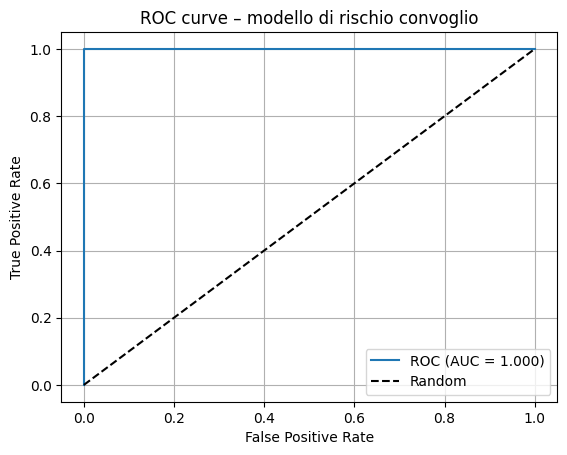

In [10]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve – modello di rischio convoglio")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds_to_try = [0.3, 0.5, 0.7]

rows = []

for thr in thresholds_to_try:
    y_pred_thr = (y_proba >= thr).astype(int)

    prec = precision_score(y_test, y_pred_thr, zero_division=0)
    rec = recall_score(y_test, y_pred_thr, zero_division=0)
    f1 = f1_score(y_test, y_pred_thr, zero_division=0)

    rows.append(
        {
            "threshold": thr,
            "precision": prec,
            "recall": rec,
            "f1": f1,
        }
    )

metrics_df = pd.DataFrame(rows)
metrics_df

,threshold,precision,recall,f1
0,0.3,1.0,1.0,1.0
1,0.5,1.0,1.0,1.0
2,0.7,1.0,1.0,1.0


In [16]:
thresholds_grid = [round(x, 2) for x in list(np.linspace(0.0, 1.0, 21))]  # 0.00, 0.05, ..., 1.00

rows = []
for thr in thresholds_grid:
    y_pred_thr = (y_proba >= thr).astype(int)
    prec = precision_score(y_test, y_pred_thr, zero_division=0)
    rec = recall_score(y_test, y_pred_thr, zero_division=0)
    rows.append({"threshold": thr, "precision": prec, "recall": rec})

thr_df = pd.DataFrame(rows)
thr_df.head()

,threshold,precision,recall
0,0.00,0.5,1.0
1,0.05,1.0,1.0
2,0.10,1.0,1.0
3,0.15,1.0,1.0
4,0.20,1.0,1.0


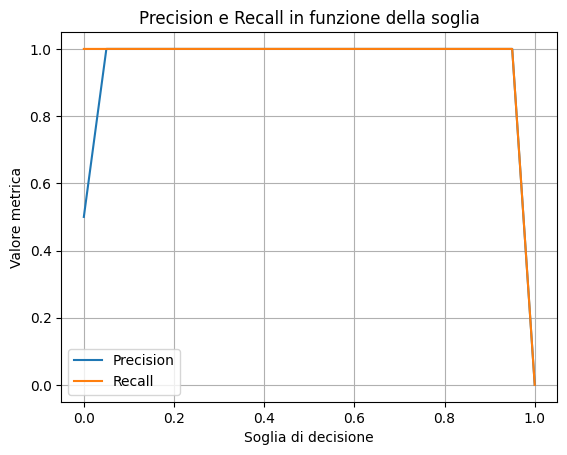

In [17]:
plt.figure()
plt.plot(thr_df["threshold"], thr_df["precision"], label="Precision")
plt.plot(thr_df["threshold"], thr_df["recall"], label="Recall")
plt.xlabel("Soglia di decisione")
plt.ylabel("Valore metrica")
plt.title("Precision e Recall in funzione della soglia")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
candidate_thresholds = [0.3, 0.4, 0.5, 0.6]

rows = []
for thr in candidate_thresholds:
    y_pred_thr = (y_proba >= thr).astype(int)
    prec = precision_score(y_test, y_pred_thr, zero_division=0)
    rec = recall_score(y_test, y_pred_thr, zero_division=0)
    f1 = f1_score(y_test, y_pred_thr, zero_division=0)

    rows.append(
        {
            "threshold": thr,
            "precision": prec,
            "recall": rec,
            "f1": f1,
        }
    )

candidate_df = pd.DataFrame(rows).sort_values("threshold")
candidate_df

,threshold,precision,recall,f1
0,0.3,1.0,1.0,1.0
1,0.4,1.0,1.0,1.0
2,0.5,1.0,1.0,1.0
3,0.6,1.0,1.0,1.0


In [21]:
best_row = candidate_df.sort_values("f1", ascending=False).iloc[0]
best_row

threshold    0.3
precision    1.0
recall       1.0
f1           1.0
Name: 0, dtype: float64

In [22]:
best_threshold = float(best_row["threshold"])
best_threshold

0.3

In [ ]:
### Scelta soglia di rischio predefinita

Dalla tabella `candidate_df` abbiamo confrontato le soglie candidate 0.3, 0.4, 0.5 e 0.6.

- Soglia X: precision = ..., recall = ..., f1 = ...
- ...

Abbiamo scelto come **soglia di rischio predefinita**:

- `risk_threshold_default = 0.3`

perché:
- [motivo 1: es. buon compromesso tra precision e recall]
- [motivo 2: es. preferiamo evitare falsi negativi, quindi accettiamo qualche falso positivo in più]